# 1. Objective
This notebook evaluates the Downstream ML Utility of our synthetic dataset using the Train on Synthetic, Test on Real (TSTR) methodology. We will train models entirely on the synthetic data and test them on the completely untouched real test set (`adult.test`). We will compare the results with the Real -> Real baseline established in Notebook 02.

# 2. Load Synthetic Training Data
We load the `adult_gaussian_copula.csv` dataset to use as our training set.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", 
    "marital-status", "occupation", "relationship", "race", "sex", 
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df_train_syn = pd.read_csv('../data/synthetic/adult_gaussian_copula.csv', skipinitialspace=True, na_values='?')
X_train = df_train_syn.drop('income', axis=1)
y_train = (df_train_syn['income'] == '>50K').astype(int)

print(f"Synthetic Training Data: {X_train.shape}")

Synthetic Training Data: (32561, 14)


# 3. Load Untouched Real Test Data
We load the `adult.test` dataset. We drop the trailing period `.` from the income target for consistency.

In [2]:
df_test_real = pd.read_csv('../data/raw/adult.test', names=columns, skiprows=1, skipinitialspace=True, na_values='?')
df_test_real['income'] = df_test_real['income'].str.rstrip('.')

X_test = df_test_real.drop('income', axis=1)
y_test = (df_test_real['income'] == '>50K').astype(int)

print(f"Real Testing Data: {X_test.shape}")

Real Testing Data: (16281, 14)


# 4. Recreate Baseline Preprocessing
We use the exact same preprocessing strategy: StandardScaler for numericals and SimpleImputer + OneHotEncoder for categoricals. Critically, we fit this ONLY on the synthetic training data.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

num_transformer = Pipeline(steps=[('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# 5. Train Logistic Regression on Synthetic Data

In [4]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

# 6. Train Random Forest on Synthetic Data

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('classifier', RandomForestClassifier(random_state=42))
])

rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

# 7. Evaluate on Real Test Data

--- Logistic Regression (Synthetic->Real) ---
Accuracy: 0.7745
ROC AUC: 0.8144
Precision: 0.8601
Recall: 0.0543
F1: 0.1022

--- Random Forest (Synthetic->Real) ---
Accuracy: 0.7666
ROC AUC: 0.7181
Precision: 0.9600
Recall: 0.0125
F1: 0.0246


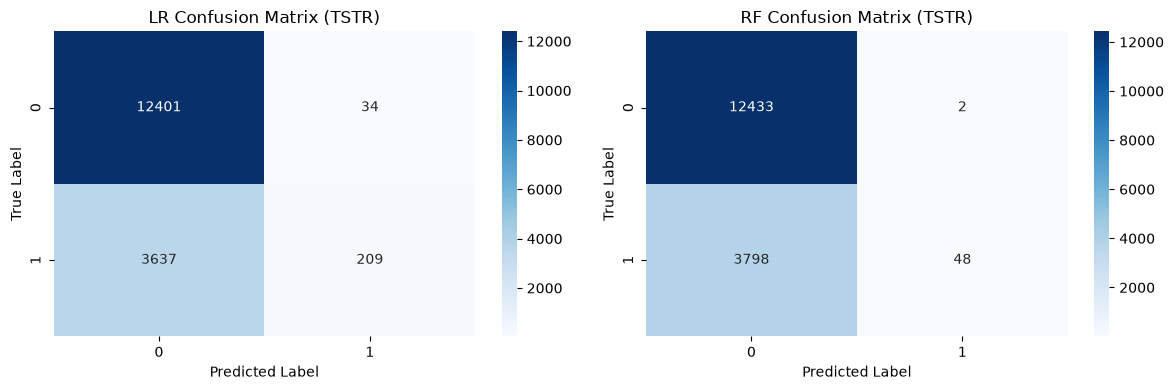

In [6]:
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def get_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'ROC AUC': roc_auc_score(y_true, y_prob),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred)
    }

metrics_lr_tstr = get_metrics(y_test, y_pred_lr, y_prob_lr)
metrics_rf_tstr = get_metrics(y_test, y_pred_rf, y_prob_rf)

print("--- Logistic Regression (Synthetic->Real) ---")
for k, v in metrics_lr_tstr.items(): print(f"{k}: {v:.4f}")

print("\n--- Random Forest (Synthetic->Real) ---")
for k, v in metrics_rf_tstr.items(): print(f"{k}: {v:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('LR Confusion Matrix (TSTR)')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('RF Confusion Matrix (TSTR)')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

# 8. Compare Real->Real vs Synthetic->Real
We hardcode the baseline results from Notebook 02 to calculate the absolute utility gap.

In [7]:
baseline_lr = {'Accuracy': 0.8530, 'ROC AUC': 0.9055, 'Precision': 0.7306, 'Recall': 0.5985, 'F1': 0.6580}
baseline_rf = {'Accuracy': 0.8499, 'ROC AUC': 0.8998, 'Precision': 0.7130, 'Recall': 0.6105, 'F1': 0.6578}

def calculate_gap(baseline, tstr):
    gap = {}
    for k in baseline.keys():
        gap[k] = baseline[k] - tstr[k]
    return gap

gap_lr = calculate_gap(baseline_lr, metrics_lr_tstr)
gap_rf = calculate_gap(baseline_rf, metrics_rf_tstr)

df_compare_lr = pd.DataFrame({'Real->Real': baseline_lr, 'Synthetic->Real': metrics_lr_tstr, 'Utility Gap': gap_lr})
df_compare_rf = pd.DataFrame({'Real->Real': baseline_rf, 'Synthetic->Real': metrics_rf_tstr, 'Utility Gap': gap_rf})

print("=== LOGISTIC REGRESSION ===")
print(df_compare_lr.round(4))
print("\n=== RANDOM FOREST ===")
print(df_compare_rf.round(4))

=== LOGISTIC REGRESSION ===
           Real->Real  Synthetic->Real  Utility Gap
Accuracy       0.8530           0.7745       0.0785
ROC AUC        0.9055           0.8144       0.0911
Precision      0.7306           0.8601      -0.1295
Recall         0.5985           0.0543       0.5442
F1             0.6580           0.1022       0.5558

=== RANDOM FOREST ===
           Real->Real  Synthetic->Real  Utility Gap
Accuracy       0.8499           0.7666       0.0833
ROC AUC        0.8998           0.7181       0.1817
Precision      0.7130           0.9600      -0.2470
Recall         0.6105           0.0125       0.5980
F1             0.6578           0.0246       0.6332


# 9. Initial Observations
Based on the Train on Synthetic, Test on Real (TSTR) experiment, we observe:

- **Collapse of Minority Class Detection**: Both models suffered a catastrophic drop in Recall (falling by ~0.54 for LR and ~0.59 for RF) and F1-score (falling by ~0.55 for LR and ~0.63 for RF). The models learned almost exclusively to predict the majority class (`<=50K`).
- **Consistency with Fidelity Findings**: In Step 6, we found that the Gaussian Copula completely failed to model `capital-gain` and `capital-loss` due to severe zero-inflation. In the real Adult dataset, high `capital-gain` is one of the strongest predictive signals for `>50K` income. Because this signal was smoothed out into statistical noise by the synthesizer, the synthetic-trained models lost their strongest indicator for the minority class, rendering them virtually unable to identify high-income individuals.
- **Precision Paradox**: Precision technically increased, but this is an artifact of the models becoming extremely conservative. Because they rarely predict `>50K`, when they finally do, they happen to be correct, but they miss 95-98% of the true positives.
- **Model Differences**: Random Forest suffered more severely than Logistic Regression in terms of ROC-AUC (gap of ~0.18 vs ~0.09). Tree-based models are more sensitive to the lack of non-linear structure that the Gaussian Copula failed to preserve.